##### Master Degree in Computer Science and Data Science for Economics and Health

# Attention: looking back at the right word

### Prof. Alfio Ferrara

## Introduction

With this notebook we enter the world of **large language models**. From here to the end of the course we build, one piece at a time, a small version of the architecture that these models share, the **Transformer** (Vaswani et al., 2017), and we use it to see how a language model is trained, adapted, explained and checked for bias. All the notebooks follow the same plan: **one toy world** (Step 1), generated by a program that we can change (`nlp/toyworld.py`), and **one model that grows**: each notebook adds an ingredient to the same code (`nlp/tinylm.py`), so that at the end the model has the structure of a real one, on a very small scale.

This choice has advantages and limits, and it is better to say them now.

- **The model is readable.** It has from a few thousand to a few tens of thousands of parameters, so we can open it: look at what each part computes, remove a part and see what changes.
- **The model is trainable here.** A training takes seconds or a few minutes on a laptop, so we can repeat an experiment, change the data and see the effect.
- **But it is not a small LLM.** What makes the real models so useful appears with **scale**: enormous corpora, billions of parameters, and abilities that nobody programmed and that we can not see in a toy (fluent text, knowledge of the world, following instructions, some form of reasoning). In the toy we can see **mechanisms**, not **capabilities**. For every result we will say what we expect to change with real models, and when we reach explainability and the use of models we will also work with real ones.

The notebook starts from the problem that L0.9 left open. We ended with a list such as `anna tea marco milk sara coffee . marco drinks`, to be answered with `milk`, and we saw that recurrent networks do not select the relevant word, and that positional embeddings make the order of the words explicit but leave each position alone: the vector of a position knows its word and its place, and nothing about the other positions. We need a mechanism with which **each position can look at the others and choose which ones matter, as a function of their content**. This is **attention**. The steps are:

1. the toy world and its data;
2. the principle of attention: a lookup that is soft and can be learned (theory, with an example built by hand);
3. a network with one layer of attention on our problem;
4. why it does not work;
5. a second layer of attention, which does;
6. how general is what the networks learned;
7. what the toy can and can not tell us, and what comes next.

A note on the **seeds**. In an experiment with a neural network, the initial weights and the random draws of the data change from one run to the other, and the result can change with them. A careful experiment is repeated with many seeds, and a phenomenon is believed only if it appears in most of them. Here we use **few seeds** (two or three) to keep the execution short, and we say in each case how many we used: read the results as an indication, not as a measure. We will see in Step 5 that even with three seeds the networks can be different from each other.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from nlp import toyworld, tinylm

warnings.filterwarnings("ignore", category=FutureWarning)

## Step 1: the toy world

> **A simple example.** Take two short texts of our world. The first is a document, `marco drinks coffee . he lives in naples .`. To continue it after `marco drinks`, a model does not need to read anything: in our world `marco` drinks `coffee` in every document, so it is enough to have **learned** it. The second is a list, `anna milk diego cocoa luca water . anna drinks`. Here the right word is `milk`, but in the world `anna` drinks `cocoa`: in this text the fact is whatever the list says, and to answer the model has to **read** it.
>
> The question of this section is: how can the same small world give us both kinds of data, those in which the answer must be known and those in which it must be read? The intuition is that the two texts are made of the same people and the same drinks, and differ in one thing only: in the first the pairs person-drink are always those of the world, in the second they are drawn again at random for every list.

The world has two layers. The first is the **meaning**: a few people, each with a gender and four attributes (drink, job, city and favourite colour), fixed once and for all when the world is created. A **fact** is a triple (person, relation, value), for example (`anna`, drink, `cocoa`). The second is the **surface**: a *language* is a set of templates that turn a fact into words. We have two of them, language A, similar to English, and language B, with other words and another order of the words (it will be the target of a translation in a later notebook). The same facts give all the kinds of data that we need: documents for language modelling, lists to read from a context (this notebook), translations, and later questions and images.

The class `ToyWorld` is built from a `WorldConfig`: the number of people, drinks, cities and colours, the relations that exist, a seed, and a parameter `job_bias` (the probability that a person has a job that the world *associates* with their gender), that we will use in the notebook on bias. A student can create a different world by changing these parameters, and generate their own dataset. This is the world with twelve people that we use here.

In [2]:
world = toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=0))
pd.DataFrame(world.table()).set_index("person")

,gender,drink,job,city,color
person,,,,,
anna,f,cocoa,farmer,milan,red
marco,m,coffee,nurse,naples,brown
luca,m,juice,mechanic,naples,yellow
sara,f,juice,clerk,genoa,red
giulia,f,milk,baker,genoa,pink
paolo,m,cocoa,teacher,rome,yellow
elena,f,coffee,dancer,turin,red
diego,m,coffee,nurse,naples,yellow
marta,f,tea,mechanic,turin,brown


A **document** says some facts of the world, one sentence for each fact. When two consecutive sentences are about the same person, the second can use a pronoun, as in `marco drinks coffee . he lives in naples`. To know who `he` is, a model has to look back at the previous sentence: it is another case of a position that needs to look at another one.

In [3]:
rng = np.random.default_rng(3)
for document in world.documents(rng, 4, n_people=2, n_facts=3):
    print(" ".join(document))

<s> marco drinks coffee . he lives in naples . marco likes brown . marta drinks tea . she is a mechanic . she lives in turin . </s>
<s> paolo lives in rome . he drinks cocoa . he is a teacher . chiara lives in bari . she is a farmer . she likes red . </s>
<s> anna is a farmer . she lives in milan . anna drinks cocoa . carlo drinks juice . he is a farmer . he lives in turin . </s>
<s> marta likes brown . marta lives in turin . she is a mechanic . diego is a nurse . diego likes yellow . he drinks coffee . </s>


### Two problems on the same data

The toy world gives data for two problems that look alike, because in both a model reads words and predicts the next one, but that ask the model to learn different things.

**Text generation** (the documents above). The model is trained to continue a document, as a language model. What it has to learn is **the world**. The facts are the same in every document (`anna drinks cocoa` here, as in any other document that talks about her drink), so the model can learn them **in its weights**, as the networks of L0.9 learned what each person drinks, and nothing in the context says which drink follows `anna drinks`. The context matters in a few places only, such as the pronouns that we saw above. And there is no single right word to check: any continuation that is well formed and true in the world is a good one.

**Recall** (the sentences below). In each text the pairs person-drink are drawn at random: in the first sentence below `anna` drinks `milk`, while in the world she drinks `cocoa`. The fact is **in the context**, and what the model has to learn is not a fact but a **procedure**: read the list, find the person that the question is about, and give the drink that the list says. There is **one right answer**, the word before `</s>`, and it is the only word of the sentence that can be predicted: the drinks of the list are random, so no model can know them before reading them. For this reason, in this notebook, loss and accuracy are computed on that word only.

Formally both problems are next-word prediction, and the difference is in what the model needs to learn to do it well: knowledge of the world in the first case, a way of looking at the context in the second. The real models do both things: they know from their weights that Rome is in Italy, and they answer a question on a text that we paste in the prompt by reading it from the context. The second ability is the one in which a model has to look back at the context and choose what to read, and it is the one where attention is needed.

In [4]:
for sentence in world.recall(rng, 4, items=3):
    print(" ".join(sentence))
print()
vocabulary = world.vocabulary()
print(f"{len(vocabulary)} words in the vocabulary of language A (including {len(toyworld.SPECIALS)} special tokens), "
      f"{len(world.vocabulary(('A', 'B')))} with language B")

<s> anna milk diego cocoa luca water . anna drinks milk </s>
<s> marta juice marco milk giulia cocoa . marco drinks milk </s>
<s> sara tea marco juice luca cocoa . sara drinks tea </s>
<s> elena coffee luca juice paolo cocoa . elena drinks coffee </s>

53 words in the vocabulary of language A (including 6 special tokens), 85 with language B


The vocabulary has 53 words for language A (with six special tokens: padding, start and end of the sentence, unknown word, mask and separator) and 85 words with language B. It is small on purpose: the model needs to learn the words of this world only.

The generator takes a seed or a `numpy` random generator, so that the data can be reproduced. To get a different world it is enough to change the configuration, for example `toyworld.ToyWorld(toyworld.WorldConfig(n_people=24, job_bias=0.8))` for 24 people with jobs that depend on gender. The data of the next steps are generated with `world.recall`.

## Step 2: attention, the principle

### From the dictionary to the soft lookup

> **A simple example.** Take the list `anna tea marco milk sara coffee . marco drinks`. If we had a dictionary we would write `memory["marco"]` and get `milk`. But think of a network that has to *learn* to answer, starting with no idea. The best that it can do at the beginning is to give one third to `tea`, one third to `milk` and one third to `coffee`, the average of the three drinks of the list. The training tells it: *more `milk`, less of the others*. With a hard choice (take one entry, drop the others) there is nothing to correct gradually: the choice is right or wrong. With weights it is different: the weight of `milk` can go from 0.33 to 0.5, to 0.9, to 1, a little at each step.
>
> The question of this section is: can we replace the choice of one entry with a **graded** choice, so that the network can improve it by gradient? The intuition is to start from the average of all the entries and to move the weights towards the entry whose name matches the question, here `marco`. When the weight of `milk` becomes close to 1 we are back to the dictionary.

For the question `marco drinks` we need the drink that the list associates with `marco`. If the list were a **dictionary** we would write `memory["marco"]` and get `milk`: a lookup compares the **query** (`marco`) with the **keys** of the memory (`anna`, `marco`, `sara`) and returns the **value** of the key that matches. The same memory can be written with vectors, and the table below shows it: each item has a key (who, as a one-hot vector) and a value (what, as a one-hot vector).

In [5]:
people_demo, drinks_demo = ["anna", "marco", "sara"], ["coffee", "tea", "milk", "juice"]
memory = {"anna": "tea", "marco": "milk", "sara": "coffee"}            # a dictionary: key -> value
print(memory["marco"])

keys = np.eye(3)                                                       # the same memory with vectors: one row per item
values = np.eye(4)[[1, 2, 0]]                                          # key = who (one-hot), value = what (one-hot)
print(pd.DataFrame(np.hstack([keys, values]), index=[f"item {i}" for i in range(3)],
                   columns=[f"key:{p}" for p in people_demo] + [f"value:{d}" for d in drinks_demo]).astype(int))

milk
        key:anna  key:marco  key:sara  value:coffee  value:tea  value:milk  \
item 0         1          0         0             0          1           0   
item 1         0          1         0             0          0           1   
item 2         0          0         1             1          0           0   

        value:juice  
item 0            0  
item 1            0  
item 2            0  


A dictionary has two limits for us. It compares **exactly**: a key is equal to the query or it is not, so a query that is only similar to a key gets nothing. And it is **not differentiable**: nothing tells us how to change keys and values by gradient to make a network answer better. **Attention** is the soft version of the lookup, in four steps:

1. every item has a **key** $k_s$ and a **value** $v_s$ (vectors), and the question is a **query** $q$ (a vector);
2. the query is compared with every key by a **dot product**, $q \cdot k_s$, which measures the similarity as the one between word vectors in L0.5: it gives a **score** for each item;
3. a **softmax** turns the scores into **weights** $a_s$: positive numbers that sum to 1, larger for the items with the larger score;
4. the answer is the **average of the values weighted by the weights**: $\sum_s a_s v_s$.

If the query is very similar to one key and different from the others, the weight of that item is near 1 and the answer is almost its value: this is the dictionary. If it is similar to several keys, the answer is a **mix** of their values. Everything is made of products, sums and softmax, so it is differentiable and the vectors involved can be learned. With the one-hot keys of the table above, the dot product of the query `marco` with its own key is 1 and with the other two is 0. The softmax of the scores $(0, 1, 0)$ is still far from a dictionary: the weight is $e/(e+2) = 0.576$ for the item that matches and $1/(e+2) = 0.212$ for each of the other two. To get a sharper choice we multiply the query by a number, a **scale** $c$: the scores become $(0, c, 0)$, and the weight of the item that matches is $e^c/(e^c+2)$, which goes to 1 as $c$ grows. The scale decides **how sharp the choice is**: with a small scale the answer is an average of all the items, with a large one it is the dictionary. It plays the role of the temperature that we used to sample text, since a temperature $\tau$ divides the scores and the scale is $1/\tau$.

The scale is not a new ingredient of attention: it is a way to see, in an example that we can read, **what the size of the scores does**. In a network nobody chooses it. How large the scores are depends on the length of the vectors $q$ and $k$, and this length is learned together with all the rest (through the matrices $W_Q$ and $W_K$ of the next section), so that a trained network can be sharp where it needs to be and vague where it does not. In the example below keys and values are made by hand, as in the table above, and the query is the one-hot vector of `marco` multiplied by four different scales.

In [6]:
def softmax(z):
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

query = np.array([0.0, 1.0, 0.0])                                      # we ask about marco
rows = {}
for scale in (1, 2, 5, 10):
    scores = keys @ (scale * query)                                    # dot product of the query with each key
    weights = softmax(scores)                                          # positive numbers that sum to 1
    answer = weights @ values                                          # weighted average of the values
    rows[scale] = {**{f"weight of {p}": w for p, w in zip(people_demo, weights)},
                   **{f"answer: {d}": a for d, a in zip(drinks_demo, answer)}}
pd.DataFrame(rows).T.rename_axis("scale of the query").round(3)

,weight of anna,weight of marco,weight of sara,answer: coffee,answer: tea,answer: milk,answer: juice
scale of the query,,,,,,,
1,0.212,0.576,0.212,0.212,0.212,0.576,0.0
2,0.107,0.787,0.107,0.107,0.107,0.787,0.0
5,0.007,0.987,0.007,0.007,0.007,0.987,0.0
10,0.000,1.000,0.000,0.000,0.000,1.000,0.0


With scale 1 the weight of `marco` is 0.576 and the other two items get 0.212 each: the answer is a mix, with 0.576 of `milk` and 0.212 of `coffee` and of `tea`. As the scale grows the weights get sharper: 0.787 with scale 2, 0.987 with scale 5, and 1.000 (to three decimals) with scale 10, where the answer is `milk` and nothing else. So the **dictionary is the limit of the soft lookup** when the scores are very different from each other: the softmax is as sharp as the size of the scores allows, and in the network the size of the scores is something that can be learned. Remember the two things that we have built by hand here, because the network will have to learn them: the **keys** must contain what we look for (who), and the **values** what we want to get (what).

### Attention in a sequence: self-attention

> **A simple example.** In `anna tea marco milk sara coffee . marco drinks`, the last word has to find `milk`. We can describe what each word does in three roles. The word `drinks` **asks**: *I am looking for the drink of `marco`*. Each drink **offers itself to be found**: `milk` says *I am the drink of `marco`*, `tea` says *I am the drink of `anna`*. And each drink has **content to hand over** when it is chosen: `milk` hands over *milk*. The same happens in a document, where in `anna is a farmer . she drinks cocoa` the word `she` asks *who is the woman that was just mentioned?*, and `anna` offers *I am a woman* and hands over *anna*.
>
> The question of this section is: where do the question, the offer and the content of each word come from, and why are they three different things? The intuition is that **one word plays three roles**: what it looks for is not what lets it be found, and neither is what it gives. The network is not told the three: it learns how to derive them from the vector of each word.

In a sequence nobody gives us queries, keys and values: we compute them from the vectors of the words. Let $x_t$ be the vector of position $t$ (embedding of the word plus position, as in L0.9). Three matrices that the network learns turn it into

$$
q_t = x_t W_Q, \qquad k_t = x_t W_K, \qquad v_t = x_t W_V.
$$

The same word has three different roles, and this is why the projections are three. The **query** says what this position is looking for. The **key** says what this position offers to be found by. The **value** is what it hands over when it is found. In the example above, a good key for a drink is *its owner*, to be found by the name, while the value is *the drink itself*, which is what we want to get: if there were a single vector, what identifies an item would have to be what we retrieve from it. The output of position $t$ is

$$
o_t = \sum_{s} a_{ts}\, v_s, \qquad a_{ts} = \frac{\exp\left(q_t \cdot k_s / \sqrt{d_k}\right)}{\sum_{u} \exp\left(q_t \cdot k_u / \sqrt{d_k}\right)},
$$

and, for all the positions at once, with the queries, keys and values as the rows of three matrices, $O = \mathrm{softmax}\left(Q K^\top / \sqrt{d_k}\right) V$. It is called **self**-attention because queries, keys and values all come from the same sequence. Two properties are worth noting. The matrices $W_Q$, $W_K$, $W_V$ do not depend on the length $T$ of the sequence: the parameters are the same for any length, as in the recurrent network, and there is no wall like the one of the window. And there is no loop on the positions: all the rows are computed with the same matrix products, at the same time.

The factor $1/\sqrt{d_k}$ needs an explanation. If the components of $q$ and $k$ are independent and have variance 1, the dot product of two vectors of dimension $d_k$ has variance $d_k$: the scores grow as $\sqrt{d_k}$ when the dimension grows. Large scores make the softmax **saturate**, with one weight near 1 and all the others near 0, and in the saturated regime the gradients are almost zero and the network learns slowly. Dividing by $\sqrt{d_k}$ keeps the scores at the same scale whatever the dimension. We check it with random vectors: for each dimension, 5,000 queries and 10 keys for each.

In [7]:
rng = np.random.default_rng(0)
rows = {}
for d in (4, 64, 1024):
    q = rng.normal(size=(5000, d))
    k = rng.normal(size=(5000, 10, d))                                 # 10 keys for each query
    s = np.einsum("nd,nkd->nk", q, k)                                  # 10 scores for each query
    rows[d] = {"std of the scores": s.std(), "std of the scores / sqrt(d)": (s / np.sqrt(d)).std(),
               "largest weight, no scaling": softmax(s).max(axis=1).mean(),
               "largest weight, scaled": softmax(s / np.sqrt(d)).max(axis=1).mean()}
pd.DataFrame(rows).T.rename_axis("dimension d").round(2)

,std of the scores,std of the scores / sqrt(d),"largest weight, no scaling","largest weight, scaled"
dimension d,,,,
4,2.00,1.00,0.49,0.30
64,8.00,1.00,0.87,0.32
1024,31.78,0.99,0.97,0.32


Without the factor the standard deviation of the scores is 2.00, 8.00 and 31.78 for $d$ = 4, 64 and 1024 (that is $\sqrt{d}$), and with it, 1.00 for all of them. The effect on the softmax is large: the largest of the 10 weights is on average 0.49, 0.87 and 0.97 without the factor, which is almost a hard choice for $d = 1024$ with keys that are random and have nothing to do with the query, and 0.30, 0.32 and 0.32 with it, which does not depend on the dimension. The factor is a property of the dot product and it will be in all the code of the next notebooks.

### The causal mask

> **A simple example.** Take the document `marco drinks coffee . he lives in naples .` and think of the model at the word `in`, that has to predict `naples`. It may read everything on its left, `marco drinks coffee . he lives in`, which tells it that `he` is `marco` and that `marco` lives in some city. It must not read `naples` or what follows: if it could, it would just copy the word to predict. At the same time, we want to compute the prediction of **all the positions of the document at once**.
>
> The question of this section is: how can all the positions work together, with the same operation, while each one sees only its own left? The intuition is a table of *who reads whom*, with one row for each word: the row of `in` has cells for `<s>`, `marco`, ..., `in`, and the cells for `naples` and the following words are covered. The same triangular cover works for all the rows.

A language model reads the position $t$ to predict the word $t+1$, so it **must not look at the positions after $t$**: otherwise it would just copy the word to predict. In the attention this is obtained by setting to $-\infty$ the scores of the positions $s > t$ before the softmax. Their weight becomes exactly 0 and each row of weights remains a distribution, now on the visible positions only. Here is the whole computation in NumPy, with a check against the PyTorch function, and the weights of a sequence of five positions with random matrices, without and with the mask.

largest difference from PyTorch (with the mask): 1.8e-15


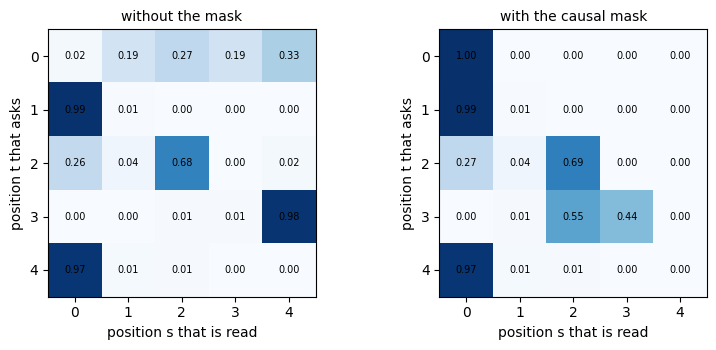

In [8]:
def attention(Q, K, V, causal=False):
    # softmax(Q K^T / sqrt(d_k)) V, one row of Q for each query; returns the output and the weights
    scores = Q @ K.T / np.sqrt(K.shape[-1])
    if causal:
        scores = np.where(np.tril(np.ones(scores.shape, dtype=bool)), scores, -np.inf)    # position t does not see s > t
    weights = softmax(scores)
    return weights @ V, weights

rng = np.random.default_rng(1)
T, d_model, d_k = 5, 8, 4
X = rng.normal(size=(T, d_model))                                      # the vectors of 5 positions
Wq, Wk, Wv = (rng.normal(size=(d_model, d_k)) for _ in range(3))       # three learned matrices (here random)
out, weights = attention(X @ Wq, X @ Wk, X @ Wv)
out_causal, weights_causal = attention(X @ Wq, X @ Wk, X @ Wv, causal=True)

reference = F.scaled_dot_product_attention(*(torch.tensor(X @ W)[None] for W in (Wq, Wk, Wv)), is_causal=True)[0].numpy()
print(f"largest difference from PyTorch (with the mask): {abs(out_causal - reference).max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, w, title in zip(axes, (weights, weights_causal), ("without the mask", "with the causal mask")):
    im = ax.imshow(w, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("position s that is read")
    ax.set_ylabel("position t that asks")
    ax.set_xticks(range(T))
    ax.set_yticks(range(T))
    for t in range(T):
        for s in range(T):
            ax.text(s, t, f"{w[t, s]:.2f}", ha="center", va="center", fontsize=7)
plt.tight_layout()

The function agrees with PyTorch up to $10^{-15}$. In the figure the matrices $W$ are random, so the weights have no meaning, but the effect of the mask is visible. Every row sums to 1 in both cases. Without the mask the first position spreads its attention on all the five (0.02, 0.19, 0.27, 0.19 and 0.33), including the future. With the mask it has only itself to read (1.00) and the upper triangle is 0. The mask does not only delete the weights of the future: it changes those of the past, because the row has to sum to 1 again. The fourth position gives 0.98 to the fifth, that is the future, without the mask, and 0.55 and 0.44 to the third and the fourth with it.

### Attention does not know the order

> **A simple example.** Take two lists, `anna tea marco milk` and `anna milk marco tea`. They contain the same four words, but they say different things: in the first `anna` drinks `tea`, in the second she drinks `milk`. What distinguishes them is only the **order**. If a model looks at the words by what they are, without knowing where they stand, the two lists are the same list: the same four words, in a different arrangement.
>
> The question of this section is: can attention tell these two lists apart? The intuition is that, by itself, it can not: shuffling the words only shuffles the results. For the order to count, each word must carry the information on where it stands before the attention starts, which is what the positional embeddings of L0.9 do. We check it on a small example.

There is one more property that we have to check. The attention compares contents: the score of two positions depends on their vectors and on nothing else. So, if we shuffle the words, nothing in the computation can tell that they were shuffled: the output of each position is the same, only in another place. In L0.9 we saw the same with the sum of the embeddings, which was the bag of words plus a constant. We check it with the five vectors above (without the mask, which is a matter of order), permuted: the output for the permuted input should be the permuted output. Then we add the positions of L0.9 to the vectors before the three projections.

In [9]:
perm = rng.permutation(T)
out, _ = attention(X @ Wq, X @ Wk, X @ Wv)
out_perm, _ = attention(X[perm] @ Wq, X[perm] @ Wk, X[perm] @ Wv)
print("perm:", perm)
print(f"without positions: largest difference between the output of the permuted input and the permuted output: "
      f"{abs(out_perm - out[perm]).max():.1e}")

PE = tinylm.sinusoid(T, d_model)
out_pos, _ = attention((X + PE) @ Wq, (X + PE) @ Wk, (X + PE) @ Wv)
out_pos_perm, _ = attention((X[perm] + PE) @ Wq, (X[perm] + PE) @ Wk, (X[perm] + PE) @ Wv)
print(f"with positions added to the vectors: the same difference is {abs(out_pos_perm - out_pos[perm]).max():.2f}")

perm: [3 1 2 0 4]
without positions: largest difference between the output of the permuted input and the permuted output: 8.9e-16
with positions added to the vectors: the same difference is 3.44


With the permutation `[3 1 2 0 4]` the difference between the output of the permuted input and the permuted output is $9 \times 10^{-16}$: zero, to the precision of the machine. **Attention alone treats the sequence as a set.** With the positions added to the vectors it is 3.44: the order is now part of the queries, keys and values, so a different order gives a different result. This is why, as in L0.9, the vector that goes in the attention is always the embedding of the word **plus** the position.

We now have the mechanism, written by hand, with the keys and values built by us. What we do not know yet is whether a network can **learn** them, from the examples of the list, and what it needs to do it.

## Step 3: one layer of attention

> **A simple example.** Take the list of the test set, `marco juice mario water chiara coffee . mario drinks`, whose answer is `water`. The position of `drinks` can look at all the words on its left, once, and give more weight to some than to others. The candidates are the three drinks, `juice`, `water` and `coffee`: we would like the weight to go to `water` and to be almost zero on the other two. This is one layer of attention.
>
> The question of this section is: can one layer of attention put the weight on `water`, in this list and in all the lists of the same kind, so that the answer is right? The intuition is that it should help a lot compared with L0.9, because the network does not mix all the drinks in the same way anymore, it can choose among them. To choose `water` the position of `drinks` has to know that it is looking for the drink of `mario`, and `water` has to be recognizable as the drink of `mario`. Whether one round of attention can arrange this is what we test.

We build the smallest network that has attention. It is a language model with the structure that we use from now on:

1. **input**: each word is replaced by its embedding, and the embedding of its position is added (as in L0.9, here the position embeddings are learned, one vector for each position, instead of the sinusoids);
2. **a layer of attention**, with the matrices $W_Q$, $W_K$, $W_V$ of Step 2 (one head, that is one attention) and an output matrix $W_O$ that mixes the result. The output is **added to the input vector**: $x \leftarrow x + \mathrm{attention}(x)$. The layer does not replace the vector of a position, it adds to it what it has read from the others, so that what the position already knew is kept (this is the *residual connection*, and the next notebook is about it);
3. **output**: a linear layer turns the final vector of each position into a score for each word of the vocabulary. The causal mask of Step 2 is always on.

There is no MLP and no normalization yet: we add them in the next notebook. The network reads the list up to the word `drinks` and the scores of the answer come from the position of `drinks`. We train it on the answer word only (cross-entropy, as we said in Step 1), with the AdamW optimizer, a learning rate that grows and then decreases during the training (3e-3 at the maximum), batches of 128 lists and 12,000 steps, on 20,000 lists of **three people** with six possible drinks. The test set is made of 2,000 new lists. We compare the results with two references: the **chance** among the six drinks of the world, and the **most frequent listed drink**, the answer of someone who has read which drinks are listed in the list and not who has which (when two drinks are equally frequent it chooses at random).

In [10]:
import time

train = torch.tensor(vocabulary.batch(world.recall(10, 20000, items=3)))               # 20,000 lists of 3 people
test = torch.tensor(vocabulary.batch(world.recall(11, 2000, items=3)))
print(" ".join(vocabulary.decode(test[0].tolist())))

# the list is <s> n1 d1 n2 d2 n3 d3 . asked drinks answer </s>: the drinks are at positions 2, 4, 6 and the question at 8
DRINK_POSITIONS = [2, 4, 6]

def asked_drink_position(sequences):
    # position of the drink of the person that the question is about
    owner = (sequences[:, [1, 3, 5]] == sequences[:, 8:9]).float().argmax(dim=1)
    return 2 + 2 * owner

def most_frequent_listed_drink(sequences, seed=0):
    # reference that has read which drinks are listed and nothing else: it answers the most frequent one (ties at random)
    rng = np.random.default_rng(seed)
    n = (sequences.shape[1] - 6) // 2                                      # people in the list
    hits = []
    for row in sequences.numpy():
        drinks, counts = np.unique(row[2:2 * n + 1:2], return_counts=True)
        hits.append(rng.choice(drinks[counts == counts.max()]) == row[-2])
    return np.mean(hits)

print(f"chance among the {len(world.values['drink'])} drinks of the world: {1 / len(world.values['drink']):.1%}")
print(f"the most frequent listed drink: {most_frequent_listed_drink(test):.1%}")

<s> marco juice mario water chiara coffee . mario drinks water </s>
chance among the 6 drinks of the world: 16.7%
the most frequent listed drink: 48.8%


In [11]:
STEPS = 12000
trained = {}

def train_models(name, seeds, **kwargs):
    for seed in seeds:
        start = time.time()
        model = tinylm.fit_recall(train, seed=seed, steps=STEPS, **kwargs)
        trained[name, seed] = model
        print(f"{name}, seed {seed}: {model.n_parameters():,} parameters, accuracy {tinylm.answer_accuracy(model, test):.1%}, "
              f"final loss {model.loss_curve[-1]:.2f}, {time.time() - start:.0f} s")

train_models("one layer", range(3), layers=1)

one layer, seed 0: 8,500 parameters, accuracy 48.3%, final loss 1.04, 15 s


one layer, seed 1: 8,500 parameters, accuracy 48.6%, final loss 1.04, 15 s


one layer, seed 2: 8,500 parameters, accuracy 48.8%, final loss 1.04, 15 s


The three networks with one layer reach 48.3%, 48.6% and 48.8%. This is the level of the reference that knows only which drinks are listed (48.8%), well above the chance (16.7%) and far from 100%, and the loss stays at 1.04 nat. The recurrent networks of L0.9 were also near the reference of the listed drinks on lists of three people (there with four drinks, here with six), and this network has 8,500 parameters, reads all the positions at once and trains in about fifteen seconds. Is the network doing what the reference does? We start from the attention. The table gives, over the 2,000 test lists, the mean weight that the position of `drinks`, the one that predicts the answer, gives to each of the three drinks of the list and to the drink of the person asked.

In [12]:
def attention_on_asked_drink(model, sequences, layer=-1, head=0):
    # attention that the position of `drinks` (the last of the input) gives to the drink of the person asked about
    weights = model.attention_maps(sequences[:, :-2])[layer][:, head, -1, :]               # (batch, positions)
    return weights, weights[torch.arange(len(sequences)), asked_drink_position(sequences)]

rows = {}
for seed in range(3):
    weights, on_asked = attention_on_asked_drink(trained["one layer", seed], test)
    rows[f"seed {seed}"] = {**{f"drink {j + 1}": weights[:, p].mean().item() for j, p in enumerate(DRINK_POSITIONS)},
                            "all the drinks": weights[:, DRINK_POSITIONS].sum(dim=1).mean().item(),
                            "the drink of the person asked": on_asked.mean().item()}
pd.DataFrame(rows).T.rename_axis("mean attention from `drinks`").round(2)

,drink 1,drink 2,drink 3,all the drinks,the drink of the person asked
mean attention from `drinks`,,,,,
seed 0,0.16,0.16,0.15,0.47,0.16
seed 1,0.18,0.18,0.18,0.55,0.18
seed 2,0.18,0.18,0.18,0.55,0.18


The weights are about the same for the three drinks (0.15 to 0.18 each), and the weight on the drink of the person asked, 0.16 to 0.18, is the same as that on the others: **the attention does not select** the right drink. All the drinks together get 0.47 to 0.55, and the rest of the attention goes to other positions. A map of attention, however, is a weak piece of evidence on what a network does (we will come back to this in the notebooks on explainability), so we also repeat the perturbation of L0.9: we replace one drink of the list at a time with each of the other five, and we measure how much the distribution of the answer changes, with the total variation distance (0 if it does not change, 1 if it is completely different). A network that reads the drink of the person asked should change a lot when we replace that drink and not at all when we replace the others.

In [13]:
def answer_probabilities(model, sequences):
    with torch.no_grad():
        return tinylm.answer_scores(model, sequences).softmax(dim=-1)

def drink_influence(model, sequences):
    # replace one listed drink at a time by each of the other drinks and measure how much the distribution of the answer
    # changes (total variation distance, as in L0.9): mean over the replacements, for the drink of the person asked
    # about and for the other drinks of the list
    drink_ids = [vocabulary.index[d] for d in world.values["drink"]]
    base = answer_probabilities(model, sequences)
    asked = asked_drink_position(sequences)
    asked_changes, other_changes = [], []
    for position in DRINK_POSITIONS:
        changes = []
        for drink in drink_ids:
            altered = sequences.clone()
            altered[:, position] = drink
            distance = 0.5 * (base - answer_probabilities(model, altered)).abs().sum(dim=-1)
            changes.append(torch.where(sequences[:, position] != drink, distance, torch.nan))
        change = torch.stack(changes).nanmean(dim=0)
        asked_changes.append(change[asked == position])
        other_changes.append(change[asked != position])
    return torch.cat(asked_changes).mean().item(), torch.cat(other_changes).mean().item()

rows = {}
for seed in range(3):
    rows[f"seed {seed}"] = dict(zip(["drink of the person asked", "other drinks of the list"], drink_influence(trained["one layer", seed], test)))
pd.DataFrame(rows).T.round(2)

,drink of the person asked,other drinks of the list
seed 0,0.4,0.4
seed 1,0.4,0.4
seed 2,0.4,0.4


The answer changes by 0.40 when we replace the drink of the person asked and by 0.40 when we replace another drink, in all three seeds: the prediction **depends on all the drinks of the list in the same way**, and not more on the right one. This is the diagnosis that we made for the recurrent network in L0.9 (where the influence of the right drink was only a little larger than that of the others), with the same accuracy as the reference of the most frequent drink. It is consistent with a network that has learned to answer with the drinks of the list without telling whose they are. The point is that the layer of attention reads all the positions at once and chooses by content, and it still does not choose. Why?

## Step 4: why one layer is not enough

> **A simple example.** Take three lists that differ only in the person asked: `marco juice mario water chiara coffee . marco drinks`, `... . mario drinks` and `... . chiara drinks`. The right answers are `juice`, `water` and `coffee`. At the entrance of the layer, the vector of each drink is the same in the three lists (`juice` in position 2, `water` in 4, `coffee` in 6), and so is the vector of the position of `drinks`, that is position 9. What tells the three questions apart is only the word in position 8, `marco`, `mario` or `chiara`, and the query of the attention is built in position 9, that does not contain it. On the other side, the vector of `water` does not say that it belongs to `mario`.
>
> The question of this section is: what must the vector of a position contain, so that the position of `drinks` can find the right drink? The intuition is that the name has to be **on both sides**: the vector of `drinks` has to carry the name of the person asked, and the vector of each drink the name of its owner. We can test this by writing the names in the vectors ourselves, by hand, and seeing whether that was all that was missing.

Look at what the attention compares, and at what each position knows. The attention of the position of `drinks` compares a **query**, built from the vector of that position, with the **keys** of the other positions, each built from its own vector. And a vector, at the entrance of the first layer, contains **only the word and the place of its position**. This is a problem on both sides:

- the **keys**: the key of a drink says which drink it is and where it is, but not **whose** it is, because the name of the owner is in the previous position;
- the **query**: the question is about `mario`, which is in the position before `drinks`; the query is built in the position of `drinks`, and the vector of that position does not contain the name.

So the query can not say *whose* drink it is looking for and the keys can not say *whose* they are. This is what we called in L0.9 the positions that do not talk to each other. A test of this explanation: we give each position the missing information **by hand**, and we see whether one layer is then enough. The network is the same as in Step 3, **with one layer of attention**, and only the input changes. Until now the vector of the position $t$ at the entrance of the layer was

$$
x_t = \mathrm{embedding}(w_t) + \mathrm{position}(t).
$$

In the new network it has a third term, the embedding of **the word that comes before** (taken from a second table of embeddings, learned like the first one, and for the first position the previous word is the padding):

$$
x_t = \mathrm{embedding}(w_t) + \mathrm{position}(t) + \mathrm{previous}(w_{t-1}).
$$

We call it *one layer + previous word*. The previous word is not found by the attention: it is **already in the vector** of each position, put there by the way in which we build the input. Here is what the vectors contain for the test list that we saw in Step 3.

In [14]:
words = vocabulary.decode(test[0, :-2].tolist())
for t, word in enumerate(words):
    print(f"position {t}: word {word:<8} previous word {words[t - 1] if t > 0 else '<pad>'}")

position 0: word <s>      previous word <pad>
position 1: word marco    previous word <s>
position 2: word juice    previous word marco
position 3: word mario    previous word juice
position 4: word water    previous word mario
position 5: word chiara   previous word water
position 6: word coffee   previous word chiara
position 7: word .        previous word coffee
position 8: word mario    previous word .
position 9: word drinks   previous word mario


The vector of each drink now contains the name of its owner (`juice` carries `marco`, `water` carries `mario`, `coffee` carries `chiara`), and the vector of `drinks` contains the name of the person asked (`mario`). So the query and the keys of the attention have what they lacked, and one layer of attention is, in principle, enough. If our explanation is right, this network should solve the problem. We train it for two seeds, with the same data, optimizer and number of steps as before, and we compare it with the networks of Step 3 on the same measures.

In [15]:
train_models("one layer + previous word", range(2), layers=1, previous_token=True)
rows = {}
for name in ("one layer", "one layer + previous word"):
    for seed in range(2):
        model = trained[name, seed]
        rows[f"{name}, seed {seed}"] = {"accuracy": tinylm.answer_accuracy(model, test),
                                        "attention on the drink of the person asked": attention_on_asked_drink(model, test)[1].mean().item(),
                                        "influence of that drink": drink_influence(model, test)[0],
                                        "influence of the other drinks": drink_influence(model, test)[1]}
pd.DataFrame(rows).T.round(2)

one layer + previous word, seed 0: 10,164 parameters, accuracy 100.0%, final loss 0.00, 16 s


one layer + previous word, seed 1: 10,164 parameters, accuracy 100.0%, final loss 0.00, 16 s


,accuracy,attention on the drink of the person asked,influence of that drink,influence of the other drinks
"one layer, seed 0",0.48,0.16,0.4,0.4
"one layer, seed 1",0.49,0.18,0.4,0.4
"one layer + previous word, seed 0",1.00,0.79,1.0,0.0
"one layer + previous word, seed 1",1.00,0.88,1.0,0.0


The two networks with the previous word reach 100.0% (two seeds), the attention on the drink of the person asked goes from 0.16-0.18 to 0.79 and 0.88, and the answer depends entirely on that drink: the influence is 1.00 for the drink of the person asked and 0.00 for the others (the networks with the plain input had 0.40 for both). The explanation holds in this test: **the problem was the information available to the queries and to the keys, not the lack of capacity or the lack of attention**. We can not conclude that it is the only possible explanation, but it makes a prediction that was confirmed.

But we gave the network the previous word by hand, and this is not a solution for a language model: what a position needs depends on the task, and in general we do not know it in advance. We need the network to **find it by itself**.

## Step 5: a second layer of attention

> **A simple example.** On the list `marco juice mario water chiara coffee . mario drinks`, imagine two rounds. In the **first round** each word looks at the word on its left and brings it into its own vector: `juice` brings `marco`, `water` brings `mario`, `coffee` brings `chiara`, and `drinks` brings `mario`. Nobody has answered yet, but now the vectors say *juice (of marco)*, *water (of mario)*, *coffee (of chiara)* and *drinks (asks about mario)*. In the **second round** `drinks` looks for the vector that carries `mario`, finds `water`, and takes it. The first round has only moved the names, the second has done the lookup.
>
> The question of this section is: can a network learn the first round by itself, if the only thing that we reward is the final answer? The intuition is that layers are **rounds of communication**: what the first round writes in a vector is what the second round can use. And each round **adds** to the vector without erasing what was there, so that `water` is still `water` after it has brought `mario` (this is the residual connection).

A second layer can do what we did by hand. Here is how. The first layer can be used to **bring to each position something from the others**: for example, each position can read the previous one. Because the output of the layer is **added** to the vector of the position (the residual connection of Step 3), after the first layer the vector of the position of `drinks` can contain the name of the person asked, and the vector of each drink can contain the name of its owner. The second layer then works on these vectors: its queries and its keys already know the names, and it can do the lookup of Step 2. In short, the first layer prepares the keys and the queries, the second one uses them. This is what we expect, and we are going to look whether it is what happens. We train a network with two layers, with the same data, the same optimizer and the same number of steps, for three seeds.

In [16]:
train_models("two layers", range(3), layers=2)

two layers, seed 0: 12,596 parameters, accuracy 100.0%, final loss 0.00, 22 s


two layers, seed 1: 12,596 parameters, accuracy 100.0%, final loss 0.00, 23 s


two layers, seed 2: 12,596 parameters, accuracy 100.0%, final loss 0.00, 22 s


All the three networks reach 100.0%. How do they get there? The figure shows the loss of all the networks of the notebook during the training (average on blocks of 100 steps). Below the figure, the step at which the loss of each network goes below 0.5.

one layer, seed 0: the loss goes below 0.5 never
one layer, seed 1: the loss goes below 0.5 never
one layer, seed 2: the loss goes below 0.5 never
one layer + previous word, seed 0: the loss goes below 0.5 in the block of steps 700-799
one layer + previous word, seed 1: the loss goes below 0.5 in the block of steps 1500-1599
two layers, seed 0: the loss goes below 0.5 in the block of steps 3800-3899
two layers, seed 1: the loss goes below 0.5 in the block of steps 2100-2199
two layers, seed 2: the loss goes below 0.5 in the block of steps 6400-6499


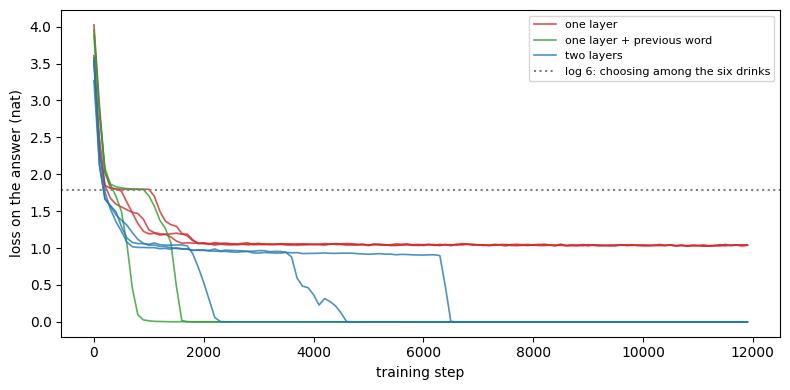

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = {"one layer": "tab:red", "one layer + previous word": "tab:green", "two layers": "tab:blue"}
for (name, seed), model in trained.items():
    ax.plot(np.arange(len(model.loss_curve)) * 100, model.loss_curve, color=colors[name], alpha=0.8, linewidth=1.2,
            label=name if seed == 0 else None)
ax.axhline(np.log(len(world.values["drink"])), color="gray", linestyle=":", label="log 6: choosing among the six drinks")
ax.set_xlabel("training step")
ax.set_ylabel("loss on the answer (nat)")
ax.legend(fontsize=8)
plt.tight_layout()

for (name, seed), model in trained.items():
    below = np.flatnonzero(model.loss_curve < 0.5)                         # the loss is averaged on blocks of 100 steps
    print(f"{name}, seed {seed}: the loss goes below 0.5 " + (f"in the block of steps {below[0] * 100}-{below[0] * 100 + 99}" if len(below) else "never"))

The networks with two layers start as the networks with one layer, on a **plateau** with a loss of about 1.0, and then the loss **falls suddenly** to zero. The moment of the fall depends on the seed: in the block of steps 2,100-2,199 for seed 1, 3,800-3,899 for seed 0 and 6,400-6,499 for seed 2. The networks with one layer and the previous word fall at 700-799 and at 1,500-1,599, and the networks with one layer do not fall at all. On the plateau the loss hardly changes, and the network that falls at 6,400 steps looked, until then, like the networks that never learn. A plausible reason, that we have not tested, is that the circuit needs two parts that work together (the first layer is useful only if the second one knows how to use it, and the other way round), so that neither is rewarded until both are there. For us the transition has a practical meaning: a training stopped after 6,000 steps would have found that seed 2 does not learn, and **the number of seeds and of steps matters for what we conclude**. In trials outside this notebook, with a previous version of the code and other settings (learning rate 1e-2 with 8,000 steps, and 1e-3 with 20,000 steps, four seeds each), some seeds remained at 48-49% for the whole training, and we chose the settings of this notebook after those trials.

<s> marco juice mario water chiara coffee . mario drinks water </s>


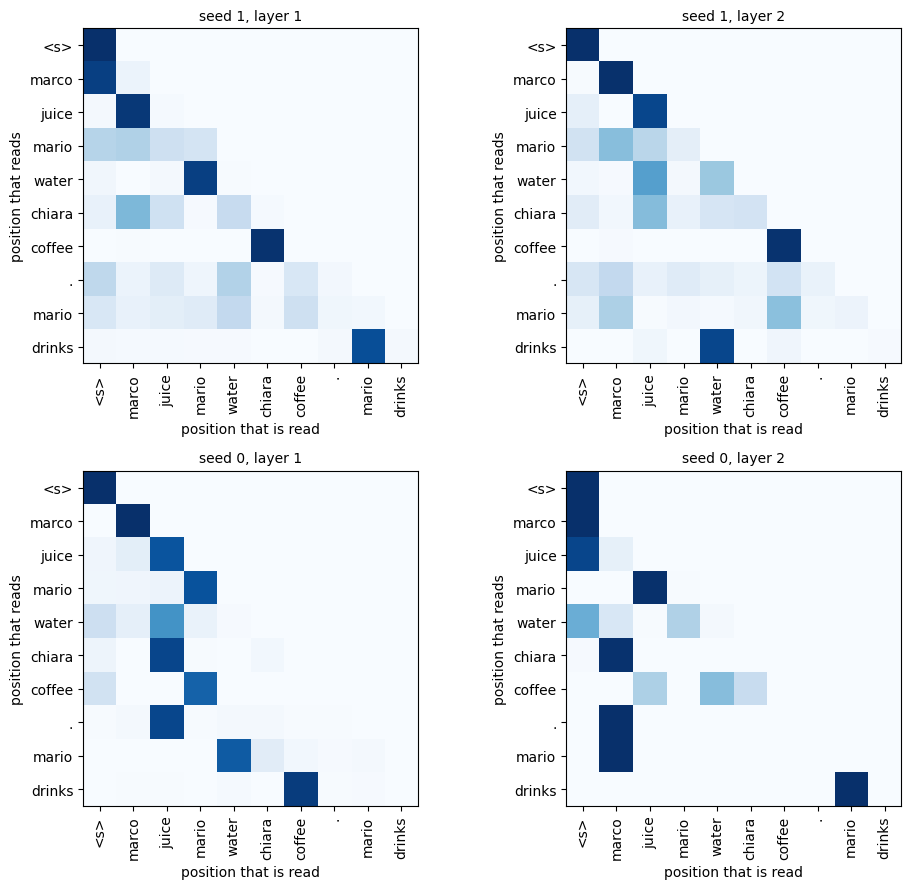

In [18]:
sequence = test[:1]
labels = vocabulary.decode(sequence[0, :-2].tolist())

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for row, seed in enumerate((1, 0)):
    maps = trained["two layers", seed].attention_maps(sequence[:, :-2])
    for ax, w, title in zip(axes[row], maps, ("layer 1", "layer 2")):
        im = ax.imshow(w[0, 0], cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=90)
        ax.set_yticks(range(len(labels)))
        ax.set_yticklabels(labels)
        ax.set_xlabel("position that is read")
        ax.set_ylabel("position that reads")
        ax.set_title(f"seed {seed}, {title}", fontsize=10)
plt.tight_layout()
print(" ".join(vocabulary.decode(sequence[0].tolist())))

The figure shows the attention of the two layers on a test list (`marco juice mario water chiara coffee . mario drinks`: the answer is `water`), for two of the three networks. For seed 1 (top), the first layer does what we expected: each drink reads the word before it (`juice` reads `marco`, `water` reads `mario`, `coffee` reads `chiara`), and the position of `drinks` reads `mario`, the person asked. In the second layer the position of `drinks` reads `water`: the lookup of Step 2, with queries and keys that now contain the names. For seed 0 (bottom) the picture is different, and we come back to this below. The table measures the same things on the 2,000 test lists, and adds two checks: the accuracy of the network when the attention of one layer is **removed** (each position reads only itself in that layer) and the perturbation of Step 3.

In [19]:
rows = {}
for seed in range(3):
    model = trained["two layers", seed]
    first, second = model.attention_maps(test[:, :-2])
    previous = np.mean([first[:, 0, p, p - 1].mean().item() for p in DRINK_POSITIONS])       # drink position -> the word before it
    row = {"accuracy": tinylm.answer_accuracy(model, test),
           "layer 1: drink -> previous word": previous,
           "layer 1: `drinks` -> previous word (the person asked)": first[:, 0, -1, -2].mean().item(),
           "layer 2: `drinks` -> drink of the person asked": attention_on_asked_drink(model, test, layer=1)[1].mean().item()}
    for k in range(2):
        model.layers[k].identity = True
        row[f"accuracy without the attention of layer {k + 1}"] = tinylm.answer_accuracy(model, test)
        model.layers[k].identity = False
    row["influence of the drink of the person asked"], row["influence of the other drinks"] = drink_influence(model, test)
    rows[f"seed {seed}"] = row
pd.DataFrame(rows).T.round(2).T

,seed 0,seed 1,seed 2
accuracy,1.00,1.00,1.00
layer 1: drink -> previous word,0.21,0.96,0.99
layer 1: `drinks` -> previous word (the person asked),0.01,0.87,0.78
layer 2: `drinks` -> drink of the person asked,0.00,0.94,0.98
accuracy without the attention of layer 1,0.16,0.35,0.16
accuracy without the attention of layer 2,0.46,0.19,0.20
influence of the drink of the person asked,1.00,1.00,1.00
influence of the other drinks,0.00,0.00,0.00


For seeds 1 and 2 the reading of the figure is confirmed. In the first layer each drink gives 0.96 and 0.99 of its attention to the previous word, and the position of `drinks` gives 0.87 and 0.78 to the position of the person asked. In the second layer the position of `drinks` gives 0.94 and 0.98 to the drink of the person asked. Removing the attention of the first layer brings the accuracy to 35% and 16%, and removing that of the second layer to 19% and 20%: both layers are necessary. The perturbation says that the answer depends on the drink of the person asked (influence 1.00) and on no other (0.00).

Seed 0 reaches the same accuracy by **another route**. The second layer does not look at the drinks (0.00 of attention on the drink of the person asked) and the first layer has little attention on the previous word (0.21 for the drinks and 0.01 for `drinks`), yet the answer depends on the drink of the person asked only (1.00 against 0.00), and without the attention of layer 1 the accuracy is 16%. In the figure, the second layer reads the position of the question, which has gathered what it needs in the first layer. We did not study this solution. It is a warning: with a single seed, and seed 0 is the one we would have looked at first, we could have told a wrong story about how the network does it. **An attention map says where a network looks, not why it answers**, and different trainings of the same network on the same data can find different solutions.

## Step 6: how general is what the networks learned?

> **A simple example.** All the networks were trained on lists of three people, like `marco juice mario water chiara coffee . mario drinks`. Two different rules give the right answer on all of those lists. The first: *find the name asked, and take the word after it*. The second is a rule of distances: *if the asked person is the first of the list take the word 7 places to the left of `drinks`, if it is the second take the word 5 places to the left, if it is the third take the word 3 places to the left*. Both are perfect on lists of three. Now take a list of four people, `marco juice mario water chiara coffee luca milk . marco drinks`: the first rule still gives `juice`, the second counts 7 places to the left of `drinks` (that is now in position 11) and lands on `water`.
>
> The question of this section is: have our networks learned a rule like the first, or one like the second? The intuition is that, since the two rules give the same results on the lists of the training, **only a test on lists of another length can tell them apart**.

All the networks were trained on lists of **three people**. If a network has learned the procedure *find the person asked, take their drink* it should work on lists of two, four or five people too. We test the networks of this notebook on 2,000 new lists for each length, and we compare with the reference of the most frequent listed drink for the same length. Lists of four and five people are longer than anything seen in training, and the positions after the ninth were never used by the networks.

In [20]:
lengths = [2, 3, 4, 5]
tests_by_length = {n: torch.tensor(vocabulary.batch(world.recall(20 + n, 2000, items=n))) for n in lengths}
rows = {"most frequent listed drink": {f"{n} people": most_frequent_listed_drink(tests_by_length[n]) for n in lengths}}
for (name, seed), model in trained.items():
    rows[f"{name}, seed {seed}"] = {f"{n} people": tinylm.answer_accuracy(model, tests_by_length[n]) for n in lengths}
pd.DataFrame(rows).T.rename_axis("list of").round(2)

,2 people,3 people,4 people,5 people
list of,,,,
most frequent listed drink,0.57,0.50,0.46,0.45
"one layer, seed 0",0.59,0.51,0.44,0.44
"one layer, seed 1",0.56,0.50,0.36,0.39
"one layer, seed 2",0.58,0.50,0.44,0.36
"one layer + previous word, seed 0",0.93,1.00,0.94,0.82
"one layer + previous word, seed 1",0.99,1.00,0.95,0.88
"two layers, seed 0",0.59,1.00,0.39,0.33
"two layers, seed 1",0.42,1.00,0.35,0.33
"two layers, seed 2",0.72,1.00,0.39,0.28


Here the results of Step 4 and Step 5 are not the same. The networks with one layer follow the reference at every length (for example 0.59, 0.56 and 0.58 against 0.57 for two people), as expected. The networks with one layer and the previous word keep a high accuracy: 0.93 and 0.99 on lists of two people, 0.94 and 0.95 on lists of four, 0.82 and 0.88 on lists of five. The **networks with two layers are at 100% on lists of three, and they fail on the others**: 0.42 to 0.72 on lists of two, 0.35 to 0.39 on lists of four, 0.28 to 0.33 on lists of five, below the reference of the most frequent drink (0.46 and 0.45 for four and five people). This holds for seeds 1 and 2, the ones with the clean attention maps. So **the maps that we read in Step 5 describe what the networks do on the lists of three, and not a procedure that works for any list**. We have not tested why. A plausible explanation is that the two layers have learned a procedure tied to the places of a list of three (for example to the positions of the drinks), which the networks with the previous word, that read the word before, depend on less; and for lists of four and five the position embeddings of the last positions were never trained.

A trial outside the notebook shows how much the training data matter. We trained the networks with two layers on lists of two, three and four people (10,000 for each length, same steps and settings). Seed 1 learned the three lengths (100% on all), seed 0 learned two and three (100% and 99.9%) and reached 77.6% on four, and seed 2 remained at the level of the reference (58%, 52%, 47%): the problem of the seeds of Step 5 comes back, stronger. None of the three reached 40% on lists of five. The network with one layer and the previous word, trained in the same way (one seed), reached 100% on two, three and four people and 86% and 80% on five and six. These are single trials and we do not show them in the notebook.

## What we learned, and what comes next

- **Attention** is a soft lookup that can be learned: each position compares a query with the keys of the others, and takes the average of their values weighted by the similarity. It reads the whole sequence at once, with the same parameters for any length, and it treats the sequence as a set unless the positions are added.
- **One layer is not enough** for our problem, because queries and keys are built from a single word and its place, and do not know the context. With the previous word added by hand, one layer solves it.
- **A second layer** can take the role of the previous word: the first layer writes into each position what it has read from the others, thanks to the residual connection, and the second layer uses it. This is what happens in two of our three networks, and in the third a different solution appears that we did not analyse.
- **The training** of this circuit has a plateau followed by a sudden fall of the loss, at a moment that depends on the seed, and the networks learn the procedure for the lists that they have seen, not necessarily for any list.

What changes with the real models. A two-layer circuit of this type, in which one attention prepares the information that another one uses to copy from the context, has been described in real language models under the name of **induction heads** (Olsson et al., 2022), and in those models too the loss shows a sudden drop during training. But a real model has tens of layers, each with many heads and an MLP, it is trained on a very large and varied corpus, and the abilities that we see here in a single task appear together with many others. The toy lets us look inside, as in Step 5, and it also shows how careful we have to be when we read what we see.

The vector that goes through the layers, that each of them reads and adds to, is the object that we studied only in part. In the next notebook we look at it directly, **the residual stream**, and we complete the layer with what was missing: several attention heads in parallel, an MLP, and the normalization of the vectors. The result is the Transformer block, the piece that a Transformer repeats.